# PROG8431 – Problem Analysis Workshop B
## K-Means Clustering on the Predictive Maintenance Dataset

| Name | Student ID |
|---|---|
| Davisen Veerasamy | 8899632 |
| Carlos Gutierrez | 9118300 |
| Nnamdi Ikengah | 9085175 |


**Dataset:** The AI4I 2020 Predictive Maintenance Dataset. It contains 10,000 runs of a milling machine, with five sensor readings per run and a record of whether (and why) the machine failed.

**GitHub Repository:** [github.com/DavisenV/Group1-PROG8431-ProblemAnalysis_Workshop_B](https://github.com/DavisenV/Group1-PROG8431-ProblemAnalysis_Workshop_B)

## 1. Setup and Configuration

**Requirement:** Python **3.14 or newer** (set in `pyproject.toml`).

Clone the repository and move into it:
```bash
git clone https://github.com/DavisenV/Group1-PROG8431-ProblemAnalysis_Workshop_B.git
cd Group1-PROG8431-ProblemAnalysis_Workshop_B
```

**Option A – uv (recommended, uses the exact versions in `uv.lock`):**
```bash
uv sync
```
Then select the `.venv` kernel in Jupyter / VS Code.

**Option B – pip:**
```bash
python -m venv .venv
# Windows (PowerShell)
.\.venv\Scripts\Activate.ps1
# macOS / Linux
source .venv/bin/activate

python -m pip install -r requirements.txt
```

The dataset is already in the `data` folder (the code below re-downloads it from UCI if it is missing).
Then run each code block below in order (or *Run All*).

### Coding Set Up

Just like the class demo, we start by clearing old plots, output and variables so the notebook runs from a clean state.

In [1]:
# Clear plots
import matplotlib.pyplot as plt
plt.close('all')

# Clear console
from IPython.display import clear_output
clear_output()

# Clean workspace
%reset -f

### Import Necessary Packages

`OMP_NUM_THREADS = 1` is set before importing KMeans (same as the class demo) to avoid a memory-leak warning on Windows.

In [2]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans

# Set up number displays
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.max_columns", None)
np.set_printoptions(suppress=True)

## 2. Download, Load, Preprocess and Clean the Dataset

We use the **same data and the same cleaning steps as Workshop A**, so the column names and results match our earlier work:

1. Download the dataset from UCI if it is not already in the `data` folder.
2. **Rename the columns** to simple snake_case names (e.g. `rotational_speed`, `torque`).
3. **Check for missing values and duplicates.**
4. **Drop `udi` and `product_id`** – these are just ID numbers, they don't describe how the machine is running.
5. **Change `type` into a categorical** variable (it is a label L/M/H, not a number).

Quick reminder of the columns:

- **type** – product quality: L (low), M (medium), H (high)
- **air_temp** and **process_temp** – temperatures in Kelvin
- **rotational_speed** – how fast the spindle spins (rpm)
- **torque** – how hard the tool is twisting, i.e. the load on it (Nm)
- **tool_wear** – how many minutes the tool has been used
- **machine_failure** – 1 if the machine failed, 0 if not
- **tool_wear_failure, heat_dissipation_failure, power_failure, overstrain_failure, random_failure** – the type of failure

In [3]:
# Define paths inside a 'data' directory
data_dir = "data"
os.makedirs(data_dir, exist_ok=True)

# UCI AI4I 2020 Predictive Maintenance dataset zip URL
dataset_url = "https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip"
zip_path = os.path.join(data_dir, "predictive_maintenance.zip")
csv_path = os.path.join(data_dir, "predictive_maintenance.csv")

# Download and extract if not present
if not os.path.exists(csv_path):
    print("Downloading dataset...")
    urllib.request.urlretrieve(dataset_url, zip_path)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(data_dir)
    os.replace(os.path.join(data_dir, "ai4i2020.csv"), csv_path)
    print(f"Dataset saved to: {csv_path}")

# Load raw dataset
df = pd.read_csv(csv_path)

print("\nFirst Few Rows")
print(df.head())


First Few Rows
   UDI Product ID Type  Air temperature [K]  Process temperature [K]  \
0    1     M14860    M              298.100                  308.600   
1    2     L47181    L              298.200                  308.700   
2    3     L47182    L              298.100                  308.500   
3    4     L47183    L              298.200                  308.600   
4    5     L47184    L              298.200                  308.700   

   Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure  TWF  \
0                    1551       42.800                0                0    0   
1                    1408       46.300                3                0    0   
2                    1498       49.400                5                0    0   
3                    1433       39.500                7                0    0   
4                    1408       40.000                9                0    0   

   HDF  PWF  OSF  RNF  
0    0    0    0    0  
1    0    0    0

In [4]:
# 1. Rename columns to cleaner standard Python identifiers (same names as Workshop A)
df.columns = [
    'udi', 'product_id', 'type', 'air_temp', 'process_temp',
    'rotational_speed', 'torque', 'tool_wear', 'machine_failure',
    'tool_wear_failure', 'heat_dissipation_failure', 'power_failure',
    'overstrain_failure', 'random_failure'
]

# 2. Check missing values & duplicates
print("Missing Values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())

# 3. Drop ID columns
df_clean = df.drop(columns=['udi', 'product_id']).copy()

# 4. Transform type into categorical
df_clean['type'] = df_clean['type'].astype('category')

print("\nCheck Format")
print(df_clean.info())

Missing Values: 0
Duplicates: 0

Check Format
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   type                      10000 non-null  category
 1   air_temp                  10000 non-null  float64 
 2   process_temp              10000 non-null  float64 
 3   rotational_speed          10000 non-null  int64   
 4   torque                    10000 non-null  float64 
 5   tool_wear                 10000 non-null  int64   
 6   machine_failure           10000 non-null  int64   
 7   tool_wear_failure         10000 non-null  int64   
 8   heat_dissipation_failure  10000 non-null  int64   
 9   power_failure             10000 non-null  int64   
 10  overstrain_failure        10000 non-null  int64   
 11  random_failure            10000 non-null  int64   
dtypes: category(1), float64(3), int64(8)
memory usage: 869.3 KB
None


There are **10,000 rows**, **no missing values** and **no duplicate rows**, so no rows need to be removed (same as we found in Workshop A).

## 3. How We Will Use Clustering

**What we already know from our earlier assignments:**

- Only **339 of 10,000 runs (3.4%)** failed, and most failures are heat dissipation (115), overstrain (98) and power (95).
- In the first assignment, the torque vs. speed scatter plot showed failures sitting at the **edges** of the operating range:
  slow + heavy load (top-left) and very fast + light load (bottom-right).
- In Workshop A, the t-test showed failed machines run at a **higher torque** (50.2 vs 39.6 Nm), and the torque of
  failed runs was **not** bell-shaped – it looked like two groups (low-torque power failures and high-torque overstrain failures).

So far we have only split the data by *failed vs. healthy*. With clustering we want to see if the machine runs
**naturally fall into groups of operating conditions** without telling the algorithm anything about failures.

Clustering is *unsupervised*, which means it does **not** look at the `machine_failure` column. After the clusters are made,
we will check the failure rate inside each cluster. If some clusters have a much higher failure rate than others,
that confirms (or challenges) what we saw before, and tells a maintenance team which operating zones are risky.

## 4. Standardize Data

Set up the two standardization functions from class.

In [5]:
# Functions to Standardize Data
# First Standardization (Min-Max, puts everything between 0 and 1)
def sta01(x):
    return (x - x.min()) / (x.max() - x.min())

# Second Standardization (Z-score, mean of 0 and standard deviation of 1)
def stamn(x):
    return (x - x.mean()) / x.std()

## 5. Explore the Data

First we look at the summary statistics, then boxplots of the numeric columns to see the spread and any outliers.

In [6]:
print(df_clean[["air_temp", "process_temp", "rotational_speed", "torque", "tool_wear"]].describe())

       air_temp  process_temp  rotational_speed    torque  tool_wear
count 10000.000     10000.000         10000.000 10000.000  10000.000
mean    300.005       310.006          1538.776    39.987    107.951
std       2.000         1.484           179.284     9.969     63.654
min     295.300       305.700          1168.000     3.800      0.000
25%     298.300       308.800          1423.000    33.200     53.000
50%     300.100       310.100          1503.000    40.100    108.000
75%     301.500       311.100          1612.000    46.800    162.000
max     304.500       313.800          2886.000    76.600    253.000


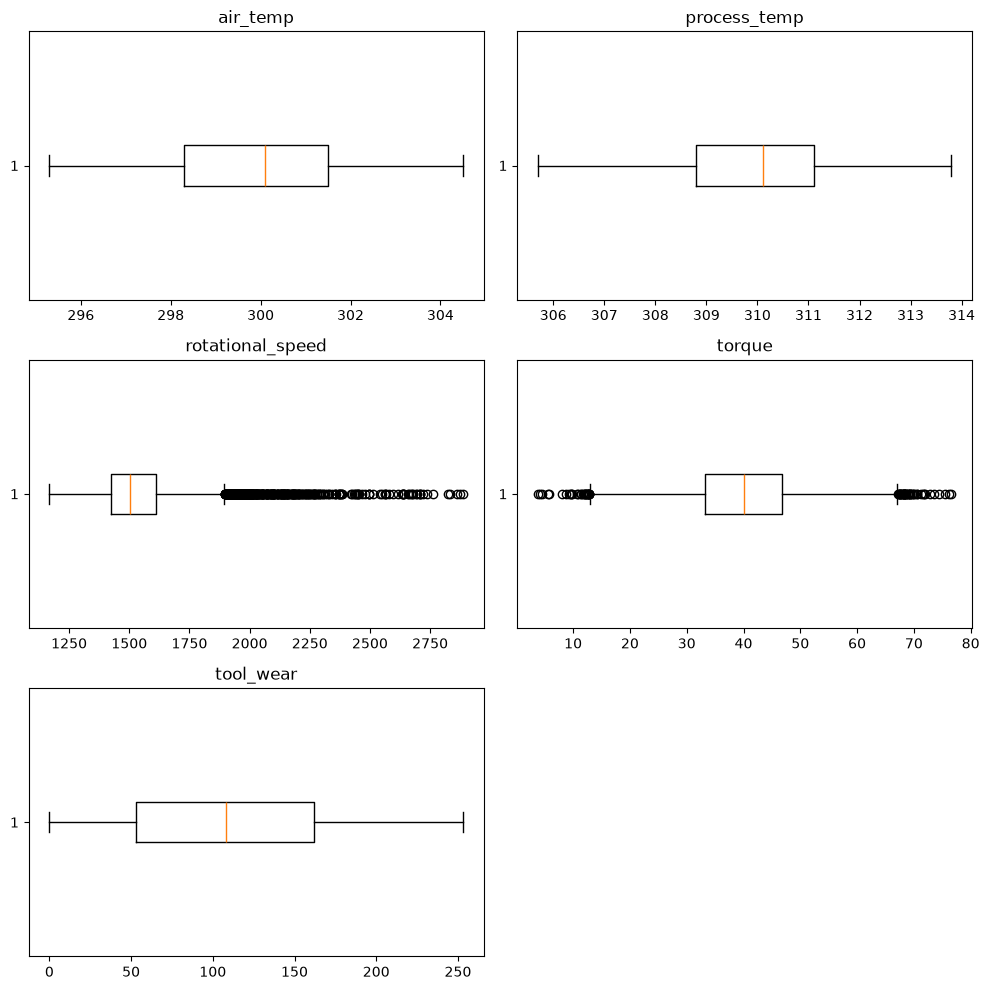

In [7]:
numeric_cols = ["air_temp", "process_temp", "rotational_speed", "torque", "tool_wear"]

fig, axes = plt.subplots(3, 2, figsize=(10, 10))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    axes[i].boxplot(df_clean[col], orientation="horizontal")
    axes[i].set_title(col)

# Hide the empty 6th plot
axes[5].axis("off")

plt.tight_layout()
plt.show()

We also check the correlation between the numeric columns. This helps us pick two variables that give different information.

In [8]:
print(df_clean[numeric_cols].corr().round(2))

                  air_temp  process_temp  rotational_speed  torque  tool_wear
air_temp             1.000         0.880             0.020  -0.010      0.010
process_temp         0.880         1.000             0.020  -0.010      0.010
rotational_speed     0.020         0.020             1.000  -0.880      0.000
torque              -0.010        -0.010            -0.880   1.000     -0.000
tool_wear            0.010         0.010             0.000  -0.000      1.000


**What we see (this matches our earlier assignments):**

- The columns are on **very different scales**. Rotational speed is around 1,500 rpm, but torque is around 40 Nm. If we cluster without
  standardizing, speed would control the whole result just because its numbers are bigger.
- **Rotational speed has a lot of outliers on the high side** (up to 2,886 rpm). In our first assignment we found it is the only
  strongly skewed sensor (**skew ≈ 1.99**).
- **Torque** has outliers on both sides but is balanced (mean ≈ median ≈ 40). In Workshop A the Shapiro-Wilk test showed torque
  is **bell-shaped** for all 10,000 runs (W = 0.9998, p = 0.38).
- **Tool wear** has no outliers and is spread fairly evenly from 0 to about 250 minutes.
- **Air and process temperature** move together (correlation ≈ 0.88), and they have a very small range (std of only 1.5–2 K).
- **Rotational speed and torque are strongly negatively correlated (≈ -0.88)** – when the machine spins faster, the torque is lower.

## 6. Choose Centroids (and Standardize)

### Variables chosen: `rotational_speed` and `torque`

**Why these two?**

- They are the two variables that best describe **how hard the machine is working**. Mechanical power is basically
  *torque × rotational speed*, so together they describe the machine's operating condition.
- Our earlier work pointed straight at them:
  - **Torque** was the strongest single warning sign (failed median 53.7 Nm vs 39.9 Nm, and the Workshop A t-test was highly significant).
  - **Rotational speed** – the slowest quarter of runs (Q1) had a **10.2%** failure rate, and the highest-torque quarter (Q4) had **9.9%**.
  - The torque vs. speed scatter plot from our first assignment showed failures grouped at the two ends of the band.
- Three of the failure types are linked to them: **power failure** (power too low or too high), **overstrain failure**
  (high torque) and **heat dissipation failure** (low speed means less cooling).
- We did not pick the two temperatures because they are very similar to each other and have a tiny range.
- We also tried torque and tool wear (tool wear Q4 also had a higher failure rate of 6.9%), but those two have no relationship
  (correlation ≈ 0), so the points form one big "blob" and the elbow chart had no clear bend. Speed and torque gave a much clearer elbow.

### Standardization chosen: Z-score (`stamn`)

- We **must** standardize because rotational speed (≈1,500) and torque (≈40) are on very different scales.
- We picked the **z-score** method over min-max (`sta01`) because **rotational speed is right-skewed with many high outliers**.
  Min-max uses the max value, so one extreme value (2,886 rpm) would squash almost all the normal readings into a small part of the 0–1 range.
  The z-score uses the mean and standard deviation, so it is less affected by a few extreme values.
- Torque is bell-shaped (Workshop A), and the z-score is a natural fit for bell-shaped data.
- After z-score, a value of 0 means "average" and a value of +1 or -1 means "one standard deviation above or below average",
  which is easy to explain.

In [9]:
df_clean["rotational_speed_std"] = stamn(df_clean["rotational_speed"])
df_clean["torque_std"] = stamn(df_clean["torque"])

print("\nStandardized Variables")
print(df_clean.head())

# Quick check: mean should be about 0 and std should be 1
print("\nCheck mean and standard deviation")
print(df_clean[["rotational_speed_std", "torque_std"]].describe().round(2))


Standardized Variables
  type  air_temp  process_temp  rotational_speed  torque  tool_wear  \
0    M   298.100       308.600              1551  42.800          0   
1    L   298.200       308.700              1408  46.300          3   
2    L   298.100       308.500              1498  49.400          5   
3    L   298.200       308.600              1433  39.500          7   
4    L   298.200       308.700              1408  40.000          9   

   machine_failure  tool_wear_failure  heat_dissipation_failure  \
0                0                  0                         0   
1                0                  0                         0   
2                0                  0                         0   
3                0                  0                         0   
4                0                  0                         0   

   power_failure  overstrain_failure  random_failure  rotational_speed_std  \
0              0                   0               0                

## 7. Generate Clusters (Looping through possible ks)

Same loop as the class demo: we try k = 1 to 7 and save the Total, Between and Within Sum of Squares for each.

In [10]:
maxk = 7
nk = range(1, maxk + 1)
wss = np.zeros(maxk)
ratio = np.zeros(maxk)

# Variables used for clustering
X = df_clean[["rotational_speed_std", "torque_std"]]

# Place to store cluster models
cluster_models = {}

# Generate Clusters
for k in nk:

    km = KMeans(
        n_clusters=k,
        max_iter=10,
        n_init=10,
        random_state=123
    )

    km.fit(X)

    cluster_models[k] = km

    print(f"\n{'='*40}")
    print(f"k = {k}")
    print("Centers")
    print(km.cluster_centers_)

    print("\nSizes")
    sizes = np.bincount(km.labels_)
    print(sizes)

    # Total SS
    total_ss = ((X - X.mean())**2).sum().sum()

    # Within SS
    within_ss = km.inertia_

    # Between SS
    between_ss = total_ss - within_ss

    print("\nTotal Sum of Squares")
    print(total_ss)

    print("\nBetween Sum of Squares")
    print(between_ss)

    print("\nWithin Sum of Squares")
    print(within_ss)

    # Store WSS for elbow chart and the Between/Total ratio
    wss[k - 1] = within_ss
    ratio[k - 1] = between_ss / total_ss


k = 1
Centers
[[-0.  0.]]

Sizes
[10000]

Total Sum of Squares
19998.0

Between Sum of Squares
1.0913936421275139e-11

Within Sum of Squares
19997.99999999999

k = 2
Centers
[[ 0.99749503 -1.05269051]
 [-0.53640476  0.56608623]]

Sizes
[3510 6490]

Total Sum of Squares
19998.0

Between Sum of Squares
11309.930904225503

Within Sum of Squares
8688.069095774497

k = 3
Centers
[[ 0.19271568 -0.44330918]
 [-0.7343896   0.89910333]
 [ 2.08057093 -1.69832349]]

Sizes
[4544 4335 1121]

Total Sum of Squares
19998.0

Between Sum of Squares
14927.063163423356

Within Sum of Squares
5070.936836576644

k = 4
Centers
[[-0.89835933  1.22663695]
 [ 2.75307191 -1.9845861 ]
 [ 0.68889874 -0.90764303]
 [-0.26661158  0.09007184]]

Sizes
[2608  592 2639 4161]

Total Sum of Squares
19998.0

Between Sum of Squares
16615.3284859083

Within Sum of Squares
3382.671514091701

k = 5
Centers
[[-0.96183154  1.38082656]
 [ 0.32016277 -0.59132614]
 [ 4.12983858 -2.42012477]
 [-0.42258398  0.31009939]
 [ 1.51864953 

## 8. Compare Different Values of 'k' to Find Optimal

### Elbow Chart

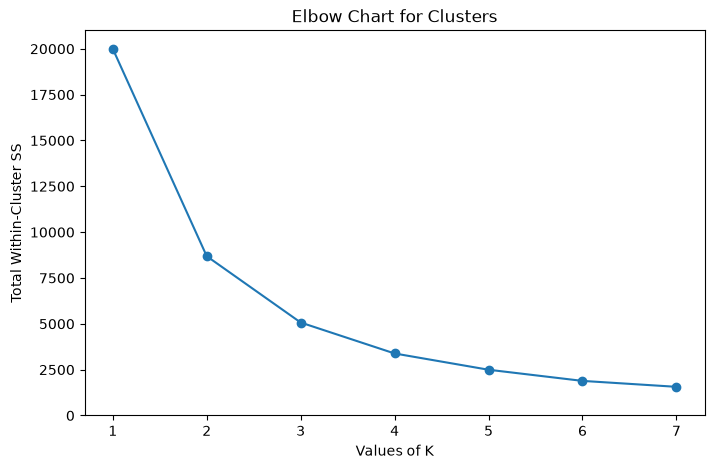

In [11]:
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, maxk + 1),
    wss,
    marker='o',
    linestyle='-'
)

plt.title("Elbow Chart for Clusters")
plt.xlabel("Values of K")
plt.ylabel("Total Within-Cluster SS")
plt.ylim(0, max(wss) * 1.05)

plt.show()

### Between SS / Total SS

Another check is the percentage of the total variation that is explained by the clusters (Between SS ÷ Total SS).
Higher is better, but we also want to see where adding more clusters stops helping much.

In [12]:
ss_table = pd.DataFrame({
    "k": list(nk),
    "Within SS": wss.round(0),
    "Between/Total (%)": (ratio * 100).round(1)
})

# How much the Within SS drops each time we add one more cluster
ss_table["Drop in Within SS"] = (-ss_table["Within SS"].diff()).round(0)

print(ss_table)

   k  Within SS  Between/Total (%)  Drop in Within SS
0  1  19998.000              0.000                NaN
1  2   8688.000             56.600          11310.000
2  3   5071.000             74.600           3617.000
3  4   3383.000             83.100           1688.000
4  5   2496.000             87.500            887.000
5  6   1887.000             90.600            609.000
6  7   1564.000             92.200            323.000


### Compare possible solutions (scatter plots)

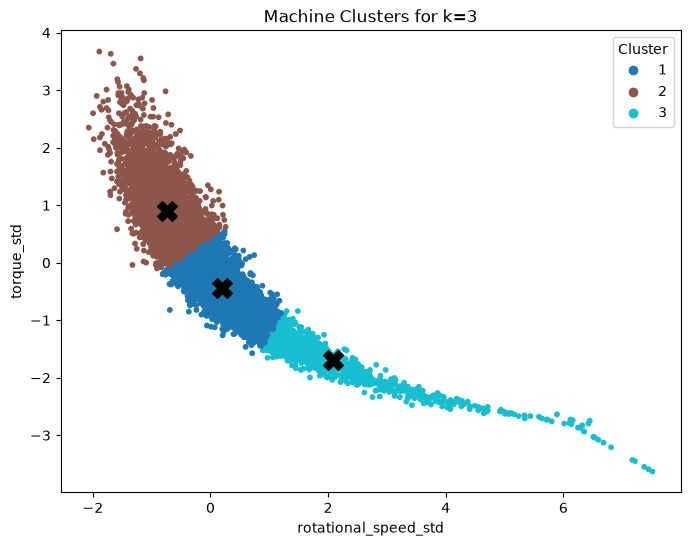

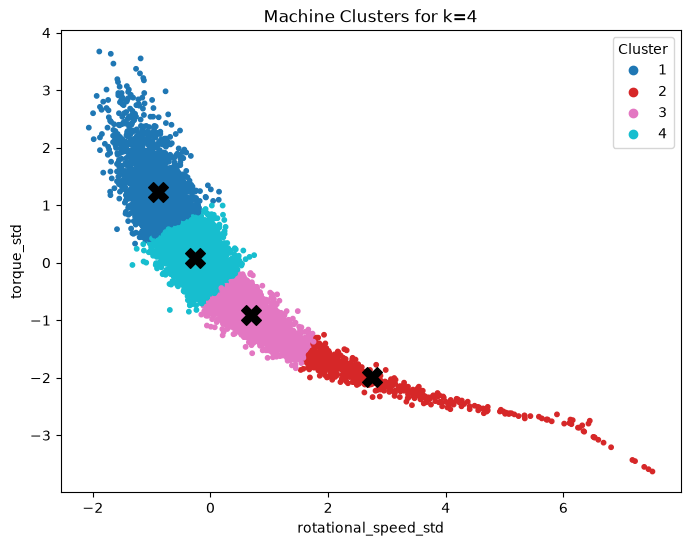

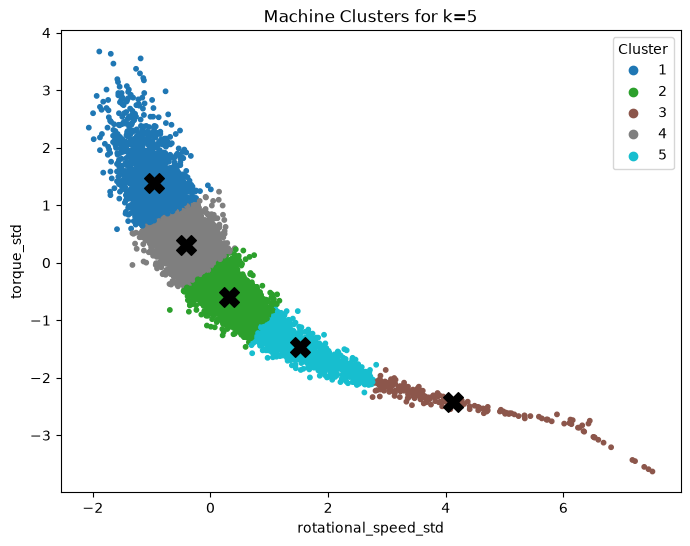

In [13]:
for k in [3, 4, 5]:

    df_clean["cluster"] = cluster_models[k].labels_ + 1

    plt.figure(figsize=(8, 6))

    scatter = plt.scatter(
        df_clean["rotational_speed_std"],
        df_clean["torque_std"],
        c=df_clean["cluster"],
        cmap="tab10",
        s=10
    )

    # Show the centres as black X's
    centres = cluster_models[k].cluster_centers_
    plt.scatter(centres[:, 0], centres[:, 1], c="black", marker="X", s=200)

    plt.title(f"Machine Clusters for k={k}")
    plt.xlabel("rotational_speed_std")
    plt.ylabel("torque_std")
    plt.legend(*scatter.legend_elements(), title="Cluster")

    plt.show()

### Our Choice: k = 4

**Elbow chart:** The Within SS drops very fast from k = 1 to k = 2 and k = 3, then the line starts to flatten out after k = 4.
After 4, each extra cluster only gives a small improvement, so the "elbow" is around **k = 3 to 4**.

**Between/Total ratio:** With k = 4 the clusters explain about **83%** of the variation, compared with about 75% for k = 3.
Going to k = 5 only adds about 4 more percentage points.

**Scatter plots:** The data forms one long diagonal band (high speed goes with low torque). With **k = 3** the
high-torque cluster is very big and mixes "normal-heavy" readings with the extreme ones. With **k = 4** the band is split into
four clear sections from "very fast / light" to "slow / heavy", and the two small clusters at the extreme ends stand out.
With **k = 5** the extra cluster just cuts the "normal" middle into more slices, which doesn't add much meaning.

So we chose **k = 4** because it is at the elbow, explains most of the variation, and each cluster is easy to describe.

## 9. Summarize Details of Final Clustering Scheme

Now we put the k = 4 cluster numbers onto the data and summarize **all** the variables (not only the two used to make the
clusters), including the failure columns.

*Note: the cluster numbers (1–4) are given by KMeans. If they come out in a different order on another computer, check the
summary table and update the names in the dictionary below.*

In [14]:
df_clean["cluster"] = cluster_models[4].labels_ + 1

print("\nCluster Assignments")
print(df_clean.head())

# Summarize Clusters (averages)
SummClusters = (
    df_clean.groupby("cluster")[["rotational_speed", "torque", "tool_wear", "air_temp", "process_temp"]]
    .mean()
    .round(1)
)

# Number of readings in each cluster
SummClusters["Count"] = df_clean.groupby("cluster").size()

print("\nCluster Summary (averages)")
print(SummClusters)


Cluster Assignments
  type  air_temp  process_temp  rotational_speed  torque  tool_wear  \
0    M   298.100       308.600              1551  42.800          0   
1    L   298.200       308.700              1408  46.300          3   
2    L   298.100       308.500              1498  49.400          5   
3    L   298.200       308.600              1433  39.500          7   
4    L   298.200       308.700              1408  40.000          9   

   machine_failure  tool_wear_failure  heat_dissipation_failure  \
0                0                  0                         0   
1                0                  0                         0   
2                0                  0                         0   
3                0                  0                         0   
4                0                  0                         0   

   power_failure  overstrain_failure  random_failure  rotational_speed_std  \
0              0                   0               0                 0.

Next, the failure rate in each cluster (as a %). Remember that KMeans never saw these columns.

In [15]:
failure_cols = ["machine_failure", "tool_wear_failure", "heat_dissipation_failure",
                "power_failure", "overstrain_failure", "random_failure"]

FailClusters = (df_clean.groupby("cluster")[failure_cols].mean() * 100).round(2)

# Shorter column names so the table fits on the screen
FailClusters.columns = ["All failures", "Tool wear", "Heat dissipation", "Power", "Overstrain", "Random"]

print("\nFailure Rate by Cluster (%)")
print(FailClusters)

print("\nOverall failure rate for the whole dataset (%):", round(df_clean["machine_failure"].mean() * 100, 2))


Failure Rate by Cluster (%)
         All failures  Tool wear  Heat dissipation  Power  Overstrain  Random
cluster                                                                      
1              10.010      0.420             4.220  2.450       3.680   0.350
2               6.250      1.010             0.000  5.240       0.000   0.000
3               0.530      0.420             0.000  0.000       0.000   0.190
4               0.650      0.430             0.120  0.000       0.050   0.120

Overall failure rate for the whole dataset (%): 3.39


Failure rates are percentages, so we also count **how many** of the 339 failures land in each cluster.

In [16]:
FailCount = df_clean.groupby("cluster")["machine_failure"].sum().to_frame("Failures")
FailCount["% of all failures"] = (FailCount["Failures"] / FailCount["Failures"].sum() * 100).round(1)
FailCount["% of all runs"] = (df_clean.groupby("cluster").size() / len(df_clean) * 100).round(1)

print(FailCount)

         Failures  % of all failures  % of all runs
cluster                                            
1             261             77.000         26.100
2              37             10.900          5.900
3              14              4.100         26.400
4              27              8.000         41.600


And how the product quality `type` is spread across the clusters (% of each cluster).

In [17]:
TypeClusters = (pd.crosstab(df_clean["cluster"], df_clean["type"], normalize="index") * 100).round(1)

print("\nProduct Type by Cluster (%)")
print(TypeClusters)


Product Type by Cluster (%)
type         H      L      M
cluster                     
1        9.700 60.500 29.800
2        9.300 59.800 30.900
3       10.100 59.900 30.000
4       10.300 59.800 29.900


### Give the Clusters Descriptive Names

In [18]:
cluster_names = {
    1: "Slow & Heavy Load",
    2: "Fast & Light Load",
    3: "Moderate-Fast, Light Load",
    4: "Normal Operation"
}

df_clean["cluster_name"] = df_clean["cluster"].map(cluster_names)

Final = SummClusters.copy()
Final["Failure %"] = FailClusters["All failures"]
Final.index = Final.index.map(cluster_names)

print(Final)

                           rotational_speed  torque  tool_wear  air_temp  \
cluster                                                                    
Slow & Heavy Load                  1377.700  52.200    107.500   300.000   
Fast & Light Load                  2032.400  20.200    106.500   300.200   
Moderate-Fast, Light Load          1662.500  30.900    109.100   300.000   
Normal Operation                   1491.000  40.900    107.700   299.900   

                           process_temp  Count  Failure %  
cluster                                                    
Slow & Heavy Load               310.000   2608     10.010  
Fast & Light Load               310.100    592      6.250  
Moderate-Fast, Light Load       310.000   2639      0.530  
Normal Operation                310.000   4161      0.650  


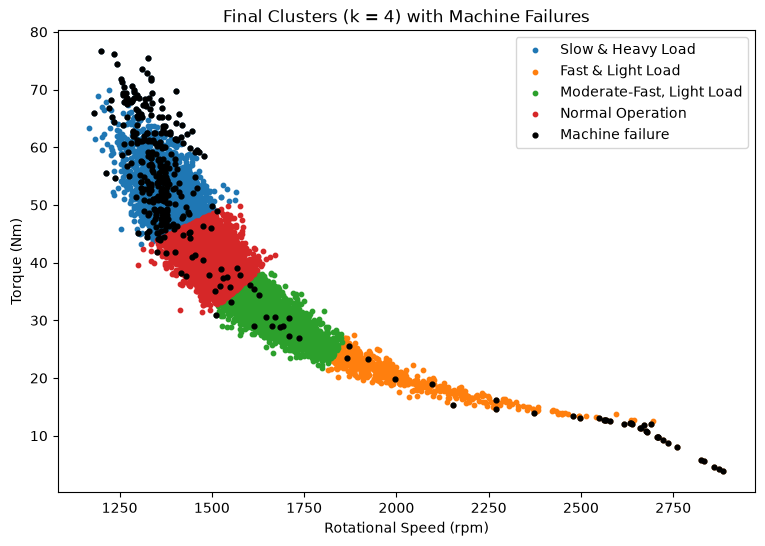

In [19]:
# Final scatter plot using the real (not standardized) values and the cluster names
plt.figure(figsize=(9, 6))

for name in cluster_names.values():
    group = df_clean[df_clean["cluster_name"] == name]
    plt.scatter(group["rotational_speed"], group["torque"], s=10, label=name)

# Show failures as black dots on top
failed = df_clean[df_clean["machine_failure"] == 1]
plt.scatter(failed["rotational_speed"], failed["torque"], c="black", s=12, label="Machine failure")

plt.title("Final Clusters (k = 4) with Machine Failures")
plt.xlabel("Rotational Speed (rpm)")
plt.ylabel("Torque (Nm)")
plt.legend()
plt.show()

## 10. Insights from the Clusters

| Cluster | Name | Avg Speed (rpm) | Avg Torque (Nm) | Runs | Failure rate |
|---|---|---|---|---|---|
| 1 | **Slow & Heavy Load** | ~1,378 | ~52 | 2,608 | **10.0%** |
| 2 | **Fast & Light Load** | ~2,032 | ~20 | 592 | **6.3%** |
| 3 | **Moderate-Fast, Light Load** | ~1,663 | ~31 | 2,639 | 0.5% |
| 4 | **Normal Operation** | ~1,491 | ~41 | 4,161 | 0.7% |

(The overall failure rate for the whole dataset is 3.4%.)

**What the clusters tell us:**

1. **Most failures happen in the two "extreme" clusters.** *Slow & Heavy Load* and *Fast & Light Load* together
   hold only about 32% of the runs, but **298 of the 339 failures (about 88%)**. The two "middle" clusters
   almost never fail (under 1%). The machine is safest when it runs in the middle of the speed/torque range.

2. **This confirms what we saw in our earlier assignments – but now the groups were found automatically.**
   In the first assignment the scatter plot showed failures in the top-left and bottom-right corners, and in Workshop A the torque
   of failed runs looked like two separate groups. KMeans never saw the `machine_failure` column, yet it still drew boundaries
   that separate the high-risk zones from the safe ones.

3. **Each extreme cluster fails in a different way.**
   - *Slow & Heavy Load* (high torque) has the most **heat dissipation** and **overstrain** failures. High torque
     puts a lot of strain on the tool, and slow speed means less cooling. This also explains the Workshop A t-test result
     (failed machines have higher average torque) – most failures come from this cluster.
   - *Fast & Light Load* has almost only **power failures**. It is the smallest cluster (592 runs) but has the highest
     power-failure rate (about 5%). These are the "low-torque" failures we saw in the Workshop A Q-Q plot.

4. **Tool wear, temperature and product type look the same in every cluster.** Average tool wear is about 107 minutes and the
   L/M/H split is about 60/30/10 in all four clusters. So the clusters are about *how* the machine is being run
   (speed and torque), not *which* product or *how old* the tool is.
   - Tool wear failures and random failures are spread out evenly, so these clusters can't predict those two types.
     Our earlier finding that worn tools (tool wear Q4) fail more often (6.9%) is a **separate** risk that speed and torque don't capture.
   - Our first assignment found that L-grade products fail more often (3.9% vs 2.1% for H). Since every cluster has the same
     product mix, that difference is **not** because L products are run at riskier speed/torque settings.

5. **Practical use:** A maintenance team could use these two sensors as an early warning. If a machine moves into the
   *Slow & Heavy Load* or *Fast & Light Load* zone, it should be checked or adjusted, because that is where the risk of failure
   jumps from under 1% to between 6% and 10%. Tool wear should still be watched separately.

6. **Next step for our term project:** speed and torque together are very useful for predicting failure, which gives us
   a good idea for a new feature to try later: **power = torque × speed**.